# 7차 실험: 시드 평균과 튜닝 설정 옮기기

| 항목 | 내용 |
|---|---|
| 목표 | 지금까지 최고(4차 또는 6차 최종)를 넘는다 |
| ① 시드 평균 | 3차 튜닝 XGBoost·LightGBM을 시드 5개로 학습해 확률 평균. 3차 단일 모델이 테스트에서 0.809로 흔들렸던 문제(분산)를 줄인다 |
| ② 튜닝 설정 옮기기 | 2차에서 앙상블 기여가 컸던 입력(+AP/TT, +PTFP, +Mordred, 입체 count FP)에 3차 튜닝 설정을 그대로 적용. 2차에서는 기본 설정이었다 |
| 비교 | 같은 10 fold, fold 안 임계값, 짝지은 보정 t-검정. 기준 = 지금까지 최고 스태킹 |

실행 약 30분. `RUN_CV = False`면 저장 결과를 불러온다.

In [1]:
import sys, time, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
HERE = Path.cwd(); M = HERE.parent
for p in ("common", "exp03_tuning"): sys.path.insert(0, str(M / p))
sys.path.insert(0, str(HERE))
from preprocess import preprocess_train
from evaluate import load_splits, run_cv
from load_features import load_all
import models7, stacking as S

warnings.filterwarnings("ignore"); sns.set_theme(style="whitegrid")
RES = HERE / "results"; RES.mkdir(exist_ok=True)
RUN_CV = True

## 1. 데이터

In [2]:
df, X, y, groups = preprocess_train(M.parent / "train.csv"); df = load_splits(df)
ALL = load_all(df, X); dev = (df.set == "dev").values
Xd = ALL[dev].reset_index(drop=True); yd = y[dev]; smi = df.loc[dev, "SMILES"].values
folds = df.loc[dev, ["fold_r0", "fold_r1"]].reset_index(drop=True)

## 2. 7차 모델 10-fold 교차검증

In [3]:
if RUN_CV:
    sc, oo = [], {}
    for name in models7.NAMES:
        mk, use = models7.build(name); t0 = time.time()
        s, o = run_cv(mk, Xd[use], yd, folds, name)
        sc.append(s)
        for r in o.columns: oo[f"{name}|{r}"] = o[r].values
        print(f"{name:34s} F1 {s.f1.mean():.4f} ± {s.f1.std(ddof=0):.4f} | AUC {s.auc.mean():.4f} | {time.time()-t0:.0f}s", flush=True)
    scores = pd.concat(sc, ignore_index=True)
    oof = pd.DataFrame(oo); oof.insert(0, "SMILES", smi); oof.insert(1, "label", yd)
    scores.to_csv(RES / "cv_scores.csv", index=False); oof.to_csv(RES / "oof_predictions.csv", index=False)
else:
    scores = pd.read_csv(RES / "cv_scores.csv"); oof = pd.read_csv(RES / "oof_predictions.csv")

seedavg|XGBoost                    F1 0.8215 ± 0.0065 | AUC 0.8829 | 954s


seedavg|LightGBM                   F1 0.8200 ± 0.0078 | AUC 0.8836 | 701s


transfer|+ap_tt|LightGBM           F1 0.8196 ± 0.0095 | AUC 0.8819 | 379s


transfer|+ptfp|LightGBM            F1 0.8186 ± 0.0100 | AUC 0.8843 | 213s


transfer|+mordred|XGBoost          F1 0.8172 ± 0.0076 | AUC 0.8781 | 1545s


transfer|count_chiral|RandomForest F1 0.8229 ± 0.0073 | AUC 0.8791 | 170s


## 3. 단독 비교

In [4]:
s2 = pd.read_csv(M / "exp02_feature_variants/results/cv_scores.csv"); s3 = pd.read_csv(M / "exp03_tuning/results/cv_scores.csv")
pairs = {"seedavg|XGBoost": (s3, "tuned|XGBoost"), "seedavg|LightGBM": (s3, "tuned|LightGBM"),
         "transfer|+ap_tt|LightGBM": (s2, "+ap_tt|LightGBM"), "transfer|+ptfp|LightGBM": (s2, "+ptfp|LightGBM"),
         "transfer|+mordred|XGBoost": (s2, "+mordred|XGBoost"), "transfer|count_chiral|RandomForest": (s2, "count_chiral|RandomForest")}
rows = []
for new, (src, old) in pairs.items():
    a = src[src.model == old].sort_values(["repeat", "fold"]); b = scores[scores.model == new].sort_values(["repeat", "fold"])
    d = b.f1.values - a.f1.values
    rows.append((new, old, a.f1.mean(), b.f1.mean(), d.mean(), S.paired_p(d), int((d > 0).sum()), a.f1.std(ddof=0), b.f1.std(ddof=0)))
single = pd.DataFrame(rows, columns=["7차 모델", "비교 대상", "이전 F1", "7차 F1", "차이", "p값", "10 fold 중 개선", "이전 F1 std", "7차 F1 std"]).set_index("7차 모델")
display(single.round(4))

,비교 대상,이전 F1,7차 F1,차이,p값,10 fold 중 개선,이전 F1 std,7차 F1 std
7차 모델,,,,,,,,
seedavg|XGBoost,tuned|XGBoost,0.8218,0.8215,-0.0003,0.8128,5,0.0059,0.0065
seedavg|LightGBM,tuned|LightGBM,0.8215,0.8200,-0.0015,0.6729,4,0.0069,0.0078
transfer|+ap_tt|LightGBM,+ap_tt|LightGBM,0.8180,0.8196,0.0015,0.6753,7,0.0078,0.0095
transfer|+ptfp|LightGBM,+ptfp|LightGBM,0.8185,0.8186,0.0001,0.9811,4,0.0077,0.0100
transfer|+mordred|XGBoost,+mordred|XGBoost,0.8165,0.8172,0.0007,0.8690,4,0.0090,0.0076
transfer|count_chiral|RandomForest,count_chiral|RandomForest,0.8191,0.8229,0.0038,0.1717,8,0.0069,0.0073


## 4. 앙상블: 지금까지 최고 vs + 7차 모델

In [5]:
pool = S.base_pool(smi); base33 = list(pool)
f6 = json.load(open(M / "exp06_knn_features/results/final_method.json"))
pool.update(S.read_oof(M / "exp06_knn_features/results/oof_predictions.csv", "6차:", smi))
best_prior_names = f6["models"] if f6["cv_f1"] > 0.8282 else base33
best_prior_label = "지금까지 최고: 6차 최종" if f6["cv_f1"] > 0.8282 else "지금까지 최고: 4차 최종"
C_prior = f6["C"] if f6["cv_f1"] > 0.8282 else 0.1
pool.update(S.read_oof(RES / "oof_predictions.csv", "7차:", smi))
new = [f"7차:{n}" for n in models7.NAMES]
methods = {"4차 최종: 스태킹 33개": S.m_stack(pool, base33, yd, C=0.1),
           best_prior_label: S.m_stack(pool, best_prior_names, yd, C=C_prior),
           "지금까지 최고 + 7차 6개": S.m_stack(pool, best_prior_names + new, yd, C=0.1),
           "지금까지 최고 + 7차 옮긴 설정 4개": S.m_stack(pool, best_prior_names + new[2:], yd, C=0.1),
           "평균: 7차 시드 평균 2개": S.m_mean(pool, new[:2])}
res = {n: S.evaluate(fn, yd, folds) for n, fn in methods.items()}
ref4 = res["4차 최종: 스태킹 33개"]["f1_thr"].values; refb = res[best_prior_label]["f1_thr"].values
rows = []
for n, r in res.items():
    d4 = r.f1_thr.values - ref4; db = r.f1_thr.values - refb
    rows.append((n, len(r), r.f1.mean(), r.f1_thr.mean(), r.f1_thr.std(ddof=0), r.auc.mean(), d4.mean(), S.paired_p(d4), db.mean(), S.paired_p(db), int((db > 0).sum())))
tbl = pd.DataFrame(rows, columns=["방법", "fold", "F1@0.5", "F1(fold 안 임계값)", "F1_std", "AUC", "4차 대비", "p(4차)", "지금까지 최고 대비", "p(최고)", "10 fold 중 개선(최고 대비)"]).drop(columns="fold")
tbl.to_csv(RES / "ensemble_compare.csv", index=False)
display(tbl.round(4))

,방법,F1@0.5,F1(fold 안 임계값),F1_std,AUC,4차 대비,p(4차),지금까지 최고 대비,p(최고),10 fold 중 개선(최고 대비)
0,4차 최종: 스태킹 33개,0.8235,0.8282,0.0070,0.8866,0.0000,NaN,0.0000,NaN,0
1,지금까지 최고: 4차 최종,0.8235,0.8282,0.0070,0.8866,0.0000,NaN,0.0000,NaN,0
2,지금까지 최고 + 7차 6개,0.8239,0.8299,0.0056,0.8882,0.0018,0.4936,0.0018,0.4936,5
3,지금까지 최고 + 7차 옮긴 설정 4개,0.8246,0.8294,0.0065,0.8883,0.0013,0.6326,0.0013,0.6326,6
4,평균: 7차 시드 평균 2개,0.8202,0.8254,0.0049,0.8836,-0.0028,0.2720,-0.0028,0.2720,3


## 5. 7차 최종 방법 확정

지금까지 최고 + 7차 6개 | 모델 수 39 | 임계값 0.42 | CV F1 0.8299


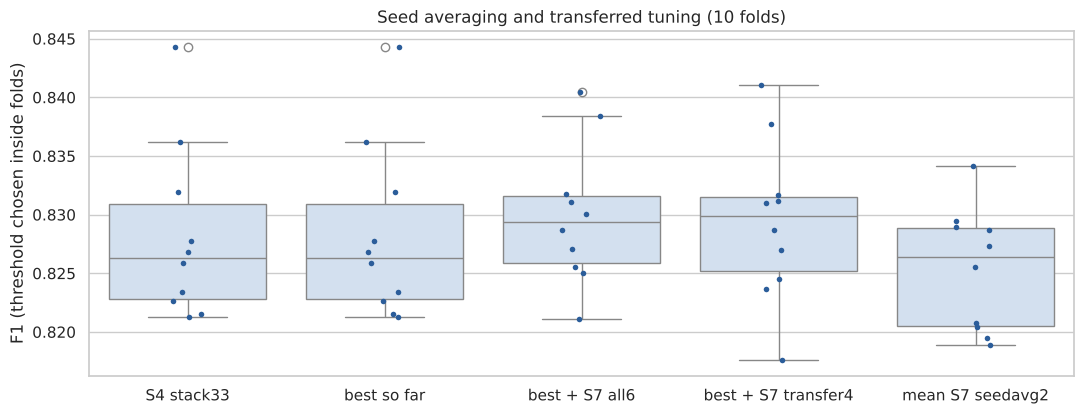

In [6]:
cand = tbl[tbl["방법"].str.contains("7차")].sort_values("F1(fold 안 임계값)", ascending=False).iloc[0]
METHOD = cand["방법"]
if METHOD.startswith("평균"):
    names = new[:2]
    p_full = np.mean([np.mean([pool[n]["r0"], pool[n]["r1"]], 0) for n in names], 0)
    final = {"method": METHOD, "kind": "mean", "models": names, "weights": [0.5, 0.5], "C": None, "intercept": None,
             "threshold": float(S.best_thr(yd, p_full)), "cv_f1": float(cand["F1(fold 안 임계값)"])}
    json.dump(final, open(RES / "final_method.json", "w"), ensure_ascii=False, indent=1)
else:
    names = best_prior_names + (new if "6개" in METHOD else new[2:])
    final = S.finalize(pool, names, yd, 0.1, RES / "final_method.json", METHOD, cand["F1(fold 안 임계값)"])
print(METHOD, "| 모델 수", len(names), "| 임계값", final["threshold"], "| CV F1", round(final["cv_f1"], 4))

long = pd.concat([r.assign(method=n) for n, r in res.items()])
en = {"4차 최종: 스태킹 33개": "S4 stack33", best_prior_label: "best so far", "지금까지 최고 + 7차 6개": "best + S7 all6",
      "지금까지 최고 + 7차 옮긴 설정 4개": "best + S7 transfer4", "평균: 7차 시드 평균 2개": "mean S7 seedavg2"}
long["method"] = long.method.map(en)
fig, ax = plt.subplots(figsize=(11, 4.3))
sns.boxplot(data=long, x="method", y="f1_thr", ax=ax, color="#cfe0f3"); sns.stripplot(data=long, x="method", y="f1_thr", ax=ax, color="#2b5d9a", size=4)
ax.set_xlabel(""); ax.set_ylabel("F1 (threshold chosen inside folds)"); ax.set_title("Seed averaging and transferred tuning (10 folds)")
plt.tight_layout(); plt.savefig(RES / "fig_seed_avg.png", dpi=130); plt.show()

## 6. 결론

결과 표와 그래프는 위 절 참고.

### 판단
1. 7차 최종은 스태킹 39개(4차 33개 + 7차 6개) + 임계값 0.42이다. CV F1 0.8299로 지금까지 가장 높다. 다만 4차 대비 +0.0018이고 p = 0.49라, 통계적으로는 4차와 같은 수준이다.
2. 시드 평균은 효과가 없었다. 튜닝된 부스팅 모델은 행·컬럼 샘플링이 있어도 시드에 따른 흔들림이 원래 작았다. 3차 테스트 점수가 낮았던 건 시드가 아니라 테스트 분할의 우연 때문으로 보인다.
3. 튜닝 설정을 옮긴 입체 count FP × RandomForest가 F1 0.8229로 지금까지 단일 모델 중 가장 높다. 3차 튜닝 설정이 다른 입력에서도 통한다는 뜻이다.
4. 단일 모델과 앙상블 모두 개선 폭이 0.002 이하로 작아지고 있다. 현재 특성과 모델 계열로는 상한(약 0.83)에 가까워졌다.

### 제출 파일
- `predict_output_임채현_7차.csv`: 스태킹 39개 + 임계값 0.42. 테스트 점수는 `results/test_score.csv`.

